# **FCNN**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
!pip install neurodiffeq

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.4/19.4 MB 87.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 119.4/119.4 kB 13.7 MB/s eta 0:00:00
  Created wheel for neurodiffeq: filename=neurodiffeq-0.6.3-py3-none-any.whl size=132419 sha256=a1f084139970d3bddad1c414f90099fa3e124d2e1fea58c9524875907ef38a45
  Stored in directory: /root/.cache/pip/wheels/f6/e7/71/84c06f693bbf2ffd52a7c5ecd416c2a2ac053569b283171ddf
Successfully built neurodiffeq


In [ ]:
from neurodiffeq import diff      # the differentiation operation
from neurodiffeq.ode import solve # the ANN-based solver
from neurodiffeq.conditions import IVP   # the initial condition
from neurodiffeq.monitors import Monitor1D
from torch.nn import L1Loss
from neurodiffeq import generators
from neurodiffeq.networks import FCNN # fully-connect neural network
import torch.nn as nn

In [ ]:
# This must be executed for Jupyter Notebook environments
# If you are using Jupyter Lab, try `%matplotlib widget`
# Don't use `%matplotlib inline`!

exponential = lambda u, t: diff(u, t) + u # specify the ODE
init_val_ex = IVP(t_0=0.0, u_0=1.0)       # specify the initial conditon

# solve the ODE
train_gener = generators.Generator1D(1022, t_min=0.0, t_max=2.0,method='equally-spaced')
net_ho = FCNN(
    n_input_units=1,
    n_output_units=1,
    hidden_units=(32,16, 8),
    actv=nn.Tanh
)
solution_ex, loss_ex = solve(ode=exponential, condition=init_val_ex,train_generator=train_gener, t_min = 0.0,t_max = 2.0,max_epochs=4000,net =net_ho)
#solution_ex, loss_ex = solve(
#    ode=exponential, condition=init_val_ex, t_min=0.0, t_max=2.0
#)

/usr/local/lib/python3.10/dist-packages/neurodiffeq/ode.py:260: FutureWarning: The `solve_system` function is deprecated, use a `neurodiffeq.solvers.Solver1D` instance instead
  warnings.warn(


ValueError: Either generator is not provided, t_min and t_max should be both provided: 
got t_min=None, t_max=None, train_generator=Generator1D(size=1022, t_min=0.0, t_max=2.0, method='uniform', noise_std=0.0004892367906066536), valid_generator=None

In [ ]:
def RungeKutta(x, y, dx, dydx):

    # Calculate slopes
    k1 = dx*dydx(x, y)
    k2 = dx*dydx(x+dx/2., y+k1/2.)
    k3 = dx*dydx(x+dx/2., y+k2/2.)
    k4 = dx*dydx(x+dx, y+k3)

    # Calculate new x and y
    y = y + 1./6*(k1+2*k2+2*k3+k4)
    x = x + dx

    return x, y
def dydx1(x, y):
    return -y
x0 = 0.
y0 = 1.
dx = 0.1
x_end = 2.
x_rk = [x0]
y_rk = [y0]

y = y0
x = x0

while x <= x_end:

    x, y = RungeKutta(x, y, dx, dydx1)

    x_rk.append(x)
    y_rk.append(y)

def Euler(x, y, dx, dydx):
    return x+dx, y+dx*dydx(x, y)

x_eu = [x0]
y_eu = [y0]

y = y0
x = x0

while x <= x_end:

    x, y = Euler(x, y, dx, dydx1)

    x_eu.append(x)
    y_eu.append(y)

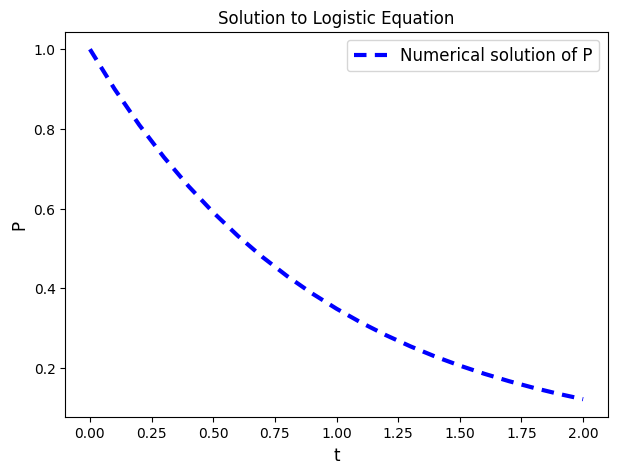

In [ ]:
plt.figure(figsize=(7,5))

plt.plot(x_eu, y_eu, label="Numerical solution of P", dashes=(3,2), color="blue",
        lw=3)

plt.legend(loc="best", fontsize=12)
plt.title(r"Solution to Logistic Equation")
plt.xlabel("t", fontsize=12)
plt.ylabel("P", fontsize=12)
plt.show()

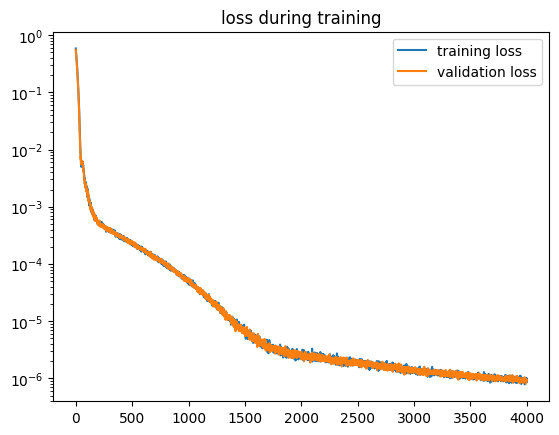

In [ ]:
plt.figure()
plt.plot(loss_ex['train_loss'], label='training loss')
plt.plot(loss_ex['valid_loss'], label='validation loss')
plt.yscale('log')
plt.title('loss during training')
plt.legend()
plt.show()

In [ ]:
#solution_ex, loss_ex = solve(
#    ode=exponential, condition=init_val_ex, t_min=0.0, t_max=2.0, criterion=L1Loss()
#)

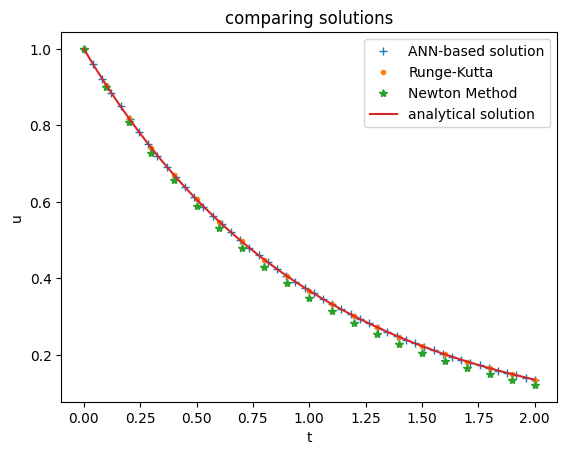

In [ ]:
ts = np.linspace(0, 2.0, 300)
u_net = solution_ex(ts, to_numpy=True)
u_ana = np.exp(-ts)

plt.figure()
plt.plot(ts, u_net, "+",  label='ANN-based solution')
plt.plot(x_rk, y_rk, ".", label='Runge-Kutta')
plt.plot(x_eu, y_eu, "*", label='Newton Method')
plt.plot(ts, u_ana, label='analytical solution')

plt.ylabel('u')
plt.xlabel('t')
plt.title('comparing solutions')
plt.legend()
plt.show()

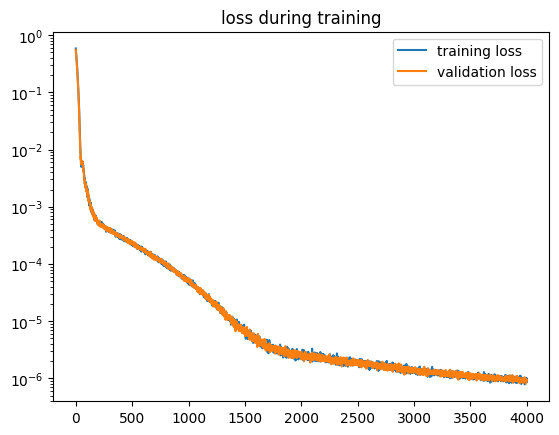

In [ ]:
plt.figure()
plt.plot(loss_ex['train_loss'], label='training loss')
plt.plot(loss_ex['valid_loss'], label='validation loss')
plt.yscale('log')
plt.title('loss during training')
plt.legend()
plt.show()

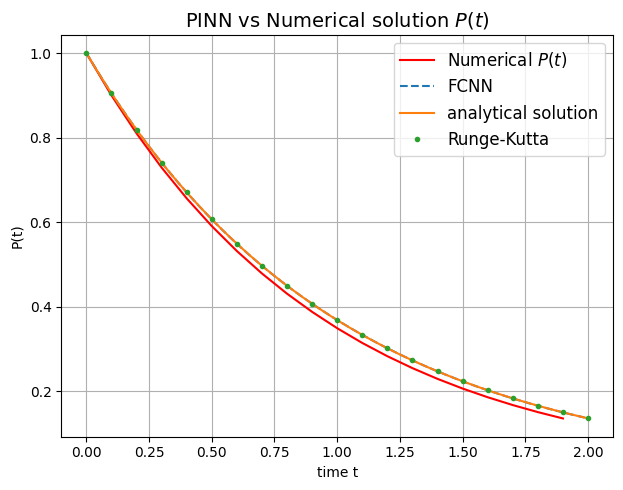

In [ ]:
plt.figure(figsize = (12,5))
plt.subplot(1,2,1)
#True Value
plt.plot(np.array(x_eu[0:-1]),np.array((y_eu))[0:-1],label ="Numerical $P(t)$",color='red')
plt.plot(ts, u_net, "--",  label='FCNN')
plt.plot(ts, u_ana, label='analytical solution')
plt.plot(x_rk, y_rk, ".", label='Runge-Kutta')
plt.title(r'PINN vs Numerical solution $P(t)$',fontsize=14)
plt.xlabel(r'time t')
plt.ylabel(r'P(t)')
plt.grid(True)
plt.legend(fontsize=12,loc = "upper right")
plt.tight_layout()
plt.show()

# **PINN**

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

# Step 1: Define the Neural Network model
def build_model():
    model = Sequential([
        Dense(32, activation='relu', input_shape=(1,)),
        Dense(16, activation='relu'),
        Dense(8, activation='relu'),
        Dense(1, activation='linear')
    ])
    return model

# Step 2: Define the physics-informed loss function
def physics_informed_loss(x, y_pred):
    # Compute the derivative of the model's output y with respect to x
    with tf.GradientTape() as tape:
        tape.watch(x)
        y = model(x)
    dy_dx = tape.gradient(y, x)

    # Physics-informed loss (PDE constraint): dy/dx + y = 0
    physics_loss = dy_dx + y

    # Compute the Mean Squared Error of the physics loss
    return tf.reduce_mean(tf.square(physics_loss))

# Step 3: Generate training data
x_train = np.random.uniform(0, 2, 1022).reshape(-1, 1)  # Sample points from the domain [0, 2]
y_train = np.exp(-x_train)  # True solution y = e^{-x}

# Convert training data to TensorFlow tensors
x_train_tensor = tf.convert_to_tensor(x_train, dtype=tf.float32)
y_train_tensor = tf.convert_to_tensor(y_train, dtype=tf.float32)

# Step 4: Build and compile the model
model = build_model()
optimizer = Adam(learning_rate=0.001)

# Custom training loop
epochs = 4000 #6000
for epoch in range(epochs):
    with tf.GradientTape() as tape:
        y_pred = model(x_train_tensor)
        # data loss
        data_loss = tf.reduce_mean(tf.square(y_train - y_pred))  # Mean squared error
        # Physics-informed loss
        pde_loss = physics_informed_loss(x_train_tensor, y_pred)
        init_loss = tf.square(y_pred[0]-1)
        # Total loss is a weighted sum of both losses
        loss = pde_loss + data_loss + init_loss

    # Compute gradients and update model weights
    gradients = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(gradients, model.trainable_variables))

    # Print the loss value periodically
    if epoch % 500 == 0:
        print(f"Epoch {epoch}: Loss = {loss.numpy()}",", y_pred[0] =",y_pred[0])

# Step 5: Test the trained model
x_test = np.linspace(0, 2, 300).reshape(-1, 1)
y_test = np.exp(-x_test)

# Predict the solution with the trained model
y_pred = model.predict(x_test)

# Plot the results
plt.figure(figsize=(8, 6))
plt.plot(x_test, y_test, label='Exact Solution $y = e^{-x}$', color='blue')
plt.plot(x_test, y_pred, label='PINN Prediction', color='red', linestyle='dashed')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.title('PINN for solving ODE: dy/dx = -y')
plt.show()

/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 0: Loss = [1.2442517] , y_pred[0] = tf.Tensor([0.02311614], shape=(1,), dtype=float32)
Epoch 500: Loss = [0.00971741] , y_pred[0] = tf.Tensor([0.96570426], shape=(1,), dtype=float32)
Epoch 1000: Loss = [0.00813758] , y_pred[0] = tf.Tensor([0.9676953], shape=(1,), dtype=float32)


KeyboardInterrupt: 

In [ ]:
pinn_pred = y_pred

In [ ]:
print(model.summary())

AttributeError: 'Model' object has no attribute 'summary'

# **DeepDE**

In [ ]:
!pip install deepxde

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 184.4/184.4 kB 13.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.8/107.8 kB 9.2 MB/s eta 0:00:00


In [ ]:
import deepxde as dde
import matplotlib.pyplot as plt

Using backend: tensorflow.compat.v1
Other supported backends: tensorflow, pytorch, jax, paddle.
paddle supports more examples now and is recommended.
Instructions for updating:
non-resource variables are not supported in the long term


No backend selected.
Finding available backend...
Found tensorflow.compat.v1
Setting the default backend to "tensorflow.compat.v1". You can change it in the ~/.deepxde/config.json file or export the DDE_BACKEND environment variable. Valid options are: tensorflow.compat.v1, tensorflow, pytorch, jax, paddle (all lowercase)


In [ ]:
import numpy as np

In [ ]:
# Define the time domain:
#T = 100
T = 2
num_samples = 1022
num_boundary = 8

# Set initial values:
x0 = 1

In [ ]:
# Define the ODE-system:
def ode_system(input, output):

    # Get the outputs:
    x = output[:, 0:1]

    # Get the derivatives:
    dx_t = dde.grad.jacobian(output, input, i=0)

    # Return the equations:
    return [dx_t + x,]

# Define the time domain of the ODE:
geom = dde.geometry.TimeDomain(0.0, T)

# Function for determening if x on boundary or not:
def boundary(_, on_initial):
    return on_initial

# Set the intial values:
ic1 = dde.IC(geom, lambda X: x0, boundary, component=0)
# Create the equation:
data = dde.data.PDE(geom, ode_system, [ic1], num_samples, num_boundary, num_test=300)

# Define a custom loss function to penalize deviations from initial condition
def custom_loss(y_true, y_pred):
    return dde.losses.mean_squared_error(y_true, y_pred) + 100 * dde.losses.mean_squared_error(y_true[0], 1)

# Define and create the neural network:
layer_size = [1] +[32]+[16]+ [8]+ [1]
activation = "Swish"
initializer = "Glorot normal"
net = dde.maps.FNN(layer_size, activation, initializer)
# Combine the data and network into a model:
model = dde.Model(data, net)
# Training:
#model.compile("adam", lr=0.01, loss=custom_loss)
model.compile("adam", lr=0.01, loss_weights= [10, 1])
losshistory, train_state = model.train(epochs=4000, display_every= 1000)

#model.compile("L-BFGS")
#losshistory, train_state = model.train()

Compiling model...
Building feed-forward neural network...
'build' took 0.194558 s

'compile' took 0.862197 s

Training model...

Step      Train loss              Test loss               Test metric
0         [2.63e-02, 1.00e+00]    [2.61e-02, 1.00e+00]    []  
1000      [2.30e-05, 6.84e-09]    [2.11e-05, 6.84e-09]    []  
2000      [5.41e-06, 4.79e-10]    [4.91e-06, 4.79e-10]    []  
3000      [4.45e-06, 2.31e-10]    [4.06e-06, 2.31e-10]    []  
4000      [3.69e-06, 1.08e-10]    [3.39e-06, 1.08e-10]    []  

Best model at step 4000:
  train loss: 3.69e-06
  test loss: 3.39e-06
  test metric: []

'train' took 13.182348 s



Compiling model...
'compile' took 0.246844 s

Training model...

Step      Train loss              Test loss               Test metric
4000      [3.69e-07, 1.08e-10]    [3.39e-07, 1.08e-10]    []  
4016      [3.69e-07, 1.08e-10]    [3.39e-07, 1.08e-10]    []  

Best model at step 4000:
  train loss: 3.69e-07
  test loss: 3.40e-07
  test metric: []

'train' took 0.438798 s



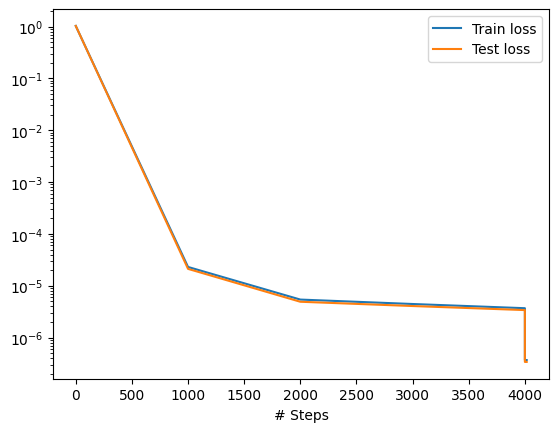

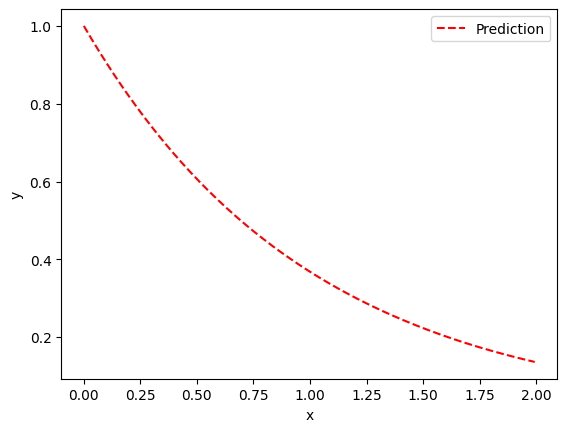

In [ ]:
model.compile("L-BFGS")
losshistory, train_state = model.train()
# Plot and save:
dde.saveplot(losshistory, train_state, issave=False, isplot=True)

In [ ]:
x=model.predict(np.expand_dims(np.linspace(0,2,300),axis=-1))[:,0]

In [ ]:
t=np.linspace(0,2,300)

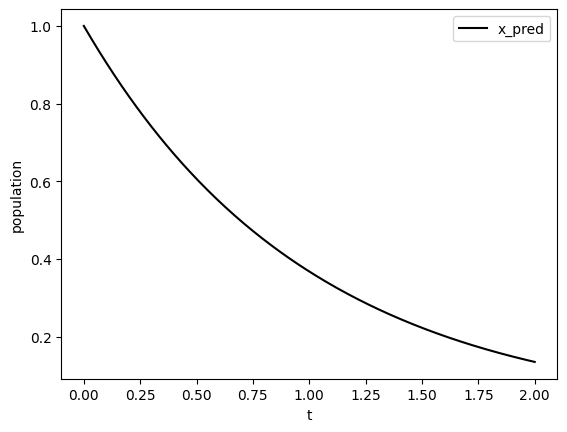

In [ ]:
# Plot the two solutions in the same plot:
t = t.reshape(300, 1)
sol_pred = model.predict(t)
x_pred_DDE = sol_pred[:, 0:1]

plt.xlabel("t")
plt.ylabel("population")
plt.plot(t, x_pred_DDE, color="black", label="x_pred")
#plt.plot(t, x_true, color="black", label="x_true", linestyle="dashed")
#plt.plot(t, y_true, color="blue", label="y_true", linestyle="dashed")
plt.legend()
plt.show()

#print("L2 relative error for x:", dde.metrics.l2_relative_error(x_true, x_pred))
#print("L2 relative error for y:", dde.metrics.l2_relative_error(y_true, y_pred))

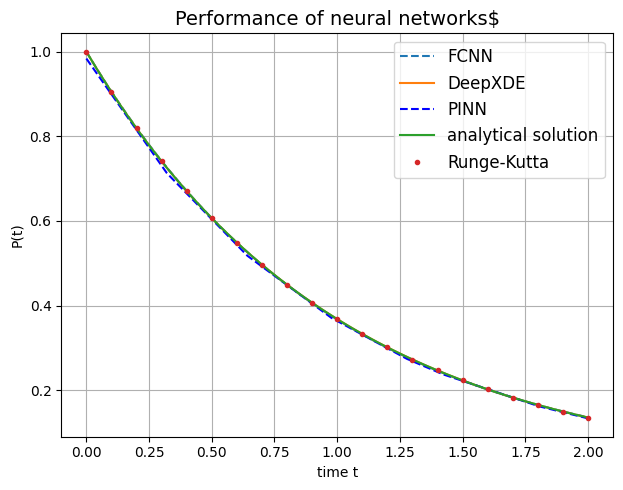

In [ ]:
plt.figure(figsize = (12,5))
plt.subplot(1,2,1)
#True Value
#plt.plot(np.array(x_eu[0:-1]),np.array((y_eu))[0:-1],label ="Numerical $P(t)$",color='red')
plt.plot(ts, u_net, "--",  label='FCNN')
plt.plot(t, x_pred_DDE,'-',label ="DeepXDE")
plt.plot(x_test,pinn_pred,'--',label ="PINN",color='blue')
plt.plot(ts, u_ana, label='analytical solution')
plt.plot(x_rk, y_rk, ".", label='Runge-Kutta')
plt.title(r'Performance of neural networks$',fontsize=14)
plt.xlabel(r'time t')
plt.ylabel(r'P(t)')
plt.grid(True)
plt.legend(fontsize=12,loc = "upper right")
plt.tight_layout()
plt.show()

In [ ]:
#L2 loss fcnn
np.sum(np.abs(np.array((u_ana))[0:]-u_net[0])**2)/300

In [ ]:
#L2 loss for PINN
np.sum((np.abs(np.array((u_ana))[0:]-pinn_pred)**2))/300

In [ ]:
#L2 loss dde
np.sum(np.abs(np.array((u_ana))[0:]-x_pred_DDE)**2)/300